# K-Means Clustering — Wine Dataset

**Classroom practical | Unsupervised Machine Learning**

We will use the **built-in Wine dataset from scikit-learn**: 178 samples and 13 numerical features. No CSV download is required.

**Learning goals:**
1. Prepare numerical features using standardization.
2. Train K-Means and inspect centroids and cluster assignments.
3. Understand **WCSS (inertia)** and the **Elbow Method**.
4. Compare K values using the **Silhouette Score**.
5. Visualize clusters using PCA and profile the results.

> **Important:** The dataset provides known wine categories, but we do **not** use their labels (`wine.target`) to train or select clusters. K-Means is unsupervised.

## 1. Import libraries

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 20)

## 2. Load and explore a standard dataset

All 13 features are numerical. Do not include a target column in `X`.

In [12]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)

print("Dataset shape:", X.shape)
print("Missing values:", X.isna().sum().sum())
display(X.head())

Dataset shape: (178, 13)
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Scale the features

K-Means uses Euclidean distances. A feature with a large scale could dominate those distances. `StandardScaler` gives each feature approximately mean 0 and standard deviation 1.

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)
print("Mean of first scaled feature:", round(X_scaled[:, 0].mean(), 3))
print("Std. dev. of first scaled feature:", round(X_scaled[:, 0].std(), 3))

Scaled shape: (178, 13)
Mean of first scaled feature: 0.0
Std. dev. of first scaled feature: 1.0


## 4. Train a first K-Means model (K = 3)

Here, `K=3` is a **starting choice for demonstration**, not a conclusion about the best number of clusters.

- `init="k-means++"`: distance-aware centroid initialization.
- `n_init=10`: try 10 initializations and retain the best result by WCSS.
- `random_state=42`: make runs reproducible.

In [14]:
model = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
labels = model.fit_predict(X_scaled)

print("Cluster sizes:")
print(pd.Series(labels, name="Cluster").value_counts().sort_index())
print("\nTotal WCSS (inertia):", round(model.inertia_, 3))
print("Centroids array shape:", model.cluster_centers_.shape)

results = X.copy()
results["Cluster"] = labels
display(results.head())

Cluster sizes:
Cluster
0    65
1    51
2    62
Name: count, dtype: int64

Total WCSS (inertia): 1277.928
Centroids array shape: (3, 13)


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,2


## 6. Visualize clusters with PCA

We have 13 features, so we use **PCA only for a 2D visualization**. The clustering itself was performed in the original 13-dimensional standardized feature space.

The centroids are projected into the same two principal components.

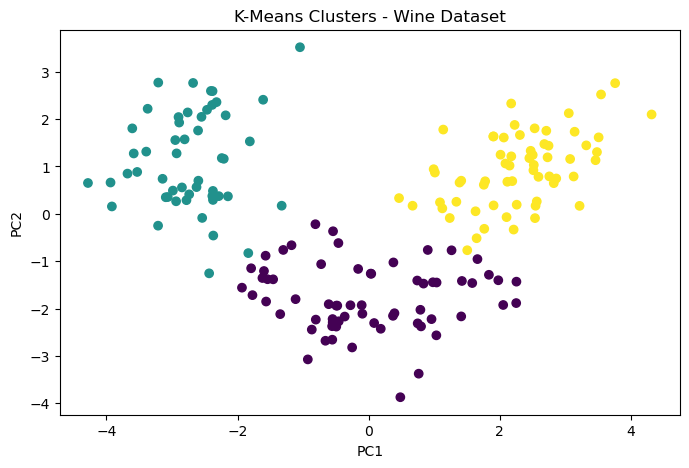

In [16]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters - Wine Dataset")
plt.show()

## 7. Elbow Method: compare total WCSS

**WCSS** is the sum of squared distances from every point to its assigned centroid. `model.inertia_` is the *total* WCSS across all clusters.

As K increases, the **best achievable** WCSS cannot increase. We look for a bend where adding further clusters gives relatively little improvement. The elbow is not always obvious.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Window

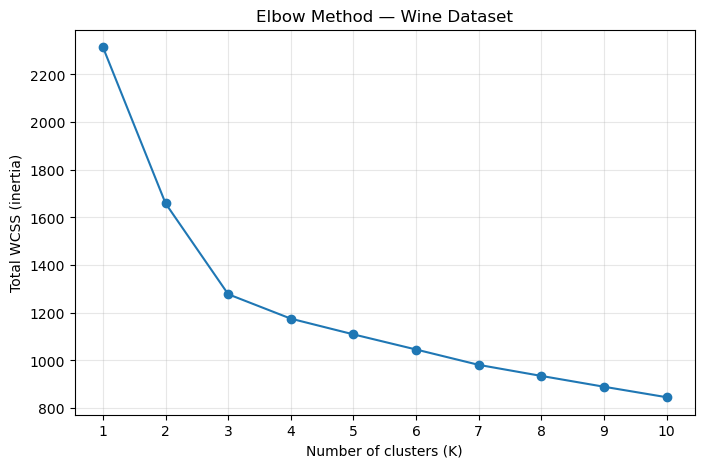

,K,WCSS
0,1,2314.00
1,2,1658.76
2,3,1277.93
3,4,1175.43
4,5,1109.51
5,6,1046.00
6,7,981.60
7,8,935.20
8,9,889.89
9,10,845.90


In [17]:
k_values_elbow = range(1, 11)
wcss = []

for k in k_values_elbow:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_elbow), wcss, marker="o")
plt.xticks(list(k_values_elbow))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Total WCSS (inertia)")
plt.title("Elbow Method — Wine Dataset")
plt.grid(alpha=0.3)
plt.show()

display(pd.DataFrame({"K": list(k_values_elbow), "WCSS": np.round(wcss, 2)}))

## 8. Silhouette Score: compare cohesion and separation

For a point *i*:

- **a(i):** Average distance from that point to other points in its **own** cluster.
- **b(i):** Lowest average distance from that point to points in any **other** cluster.

\[s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}\]

The overall score is the average of sample scores. It ranges from **-1 to +1**, with higher values generally indicating more compact and separated clusters.

We start at **K=2** because the Silhouette Score is not defined for one cluster. scikit-learn also requires the number of distinct cluster labels to be less than the number of samples.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Window

,K,Average Silhouette Score
0,2,0.259
1,3,0.285
2,4,0.260
3,5,0.202
4,6,0.237
5,7,0.204
6,8,0.157
7,9,0.150
8,10,0.144


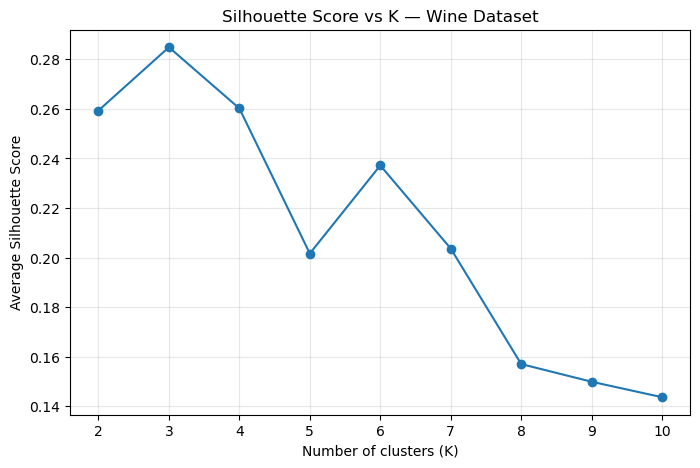

Highest Silhouette Score among the tested K values is at K = 3


In [18]:
k_values_sil = range(2, 11)
sil_scores = []

for k in k_values_sil:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    cluster_labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    sil_scores.append(score)

silhouette_results = pd.DataFrame({
    "K": list(k_values_sil),
    "Average Silhouette Score": np.round(sil_scores, 3)
})
display(silhouette_results)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_sil), sil_scores, marker="o")
plt.xticks(list(k_values_sil))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Score vs K — Wine Dataset")
plt.grid(alpha=0.3)
plt.show()

best_k = list(k_values_sil)[int(np.argmax(sil_scores))]
print("Highest Silhouette Score among the tested K values is at K =", best_k)

## 9. Fit the selected model and report evaluation metrics

For this exercise, select K using the highest tested Silhouette Score. In a real project, also inspect the Elbow plot, cluster sizes, stability and domain usefulness before making a final selection.

In [19]:
final_model = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=42)
final_labels = final_model.fit_predict(X_scaled)

print("Selected K:", best_k)
print("Final WCSS:", round(final_model.inertia_, 3))
print("Average Silhouette Score:", round(silhouette_score(X_scaled, final_labels), 3))
print("Cluster sizes:")
print(pd.Series(final_labels).value_counts().sort_index())

Selected K: 3
Final WCSS: 1277.928
Average Silhouette Score: 0.285
Cluster sizes:
0    65
1    51
2    62
Name: count, dtype: int64


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1411: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## 10. Cluster profiling — interpret the groups

To interpret clusters, compute feature averages in **original units**, not scaled values. The mean profile is a simple way to characterize each cluster.

In [20]:
profile = X.copy()
profile["Cluster"] = labels

display(profile.groupby("Cluster").mean().round(2))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Cluster,,,,,,,,,,,,,
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23
